# Project: The Supreme Intelligence 5G Transmission Coverage

<i>Konieczny Mateusz 257328 and Mikołaj Koszewski 257329, 14.11.2026 - 17.11.2026</i>

In [ ]:
from scipy.spatial.distance import pdist, squareform

import matplotlib.pyplot as plt
import numpy as np
import itertools

First in order to go through the solution let us try to understand the main problem with the simple visualisation - which we suppose may be helpful. Below we created functions to simply visualise the data.

In [2]:
def read_towers(file_path):
    """
    The function that reads the file and returns it's points, number of towers,number of towers to keep and dimension.

    :param file_path: string
    :return: tuple
    """
    with open(file_path, encoding="utf-8") as file:
        n, k, dimension = map(int, file.readline().split())
        points = np.loadtxt(file, dtype=int, ndmin=2)

    if dimension not in (2, 3):
        raise ValueError("The file must contain 2D or 3D points.")

    if points.shape != (n, dimension):
        raise ValueError("The coordinates do not match the file header.")

    return points, n, k, dimension


def plot_towers(file_path):
    points, n, k, dimension = read_towers(file_path)

    if dimension == 2:
        plt.figure(figsize=(7, 6))
        plt.scatter(points[:, 0], points[:, 1], color="steelblue", s=45)
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.title("Towers in 2D")
        plt.axis("equal")
        plt.grid(True, alpha=0.3)

    else:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(projection="3d")
        ax.scatter(
            points[:, 0], points[:, 1], points[:, 2],
            color="steelblue", s=45
        )
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")
        ax.set_title("Towers in 3D")

    plt.show()

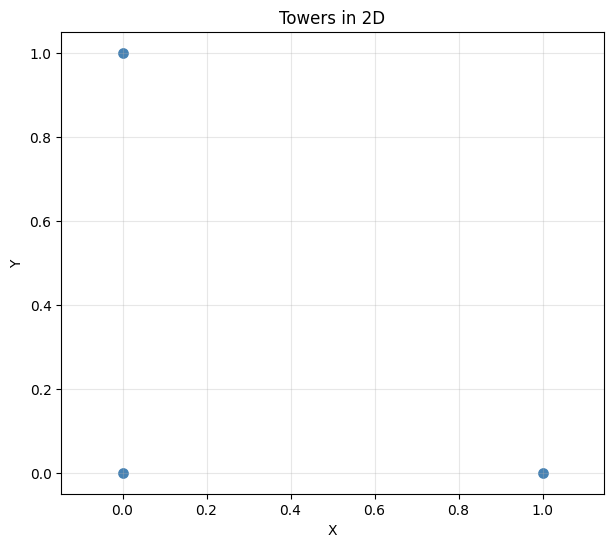

In [3]:
plot_towers("tests/test_1.txt")

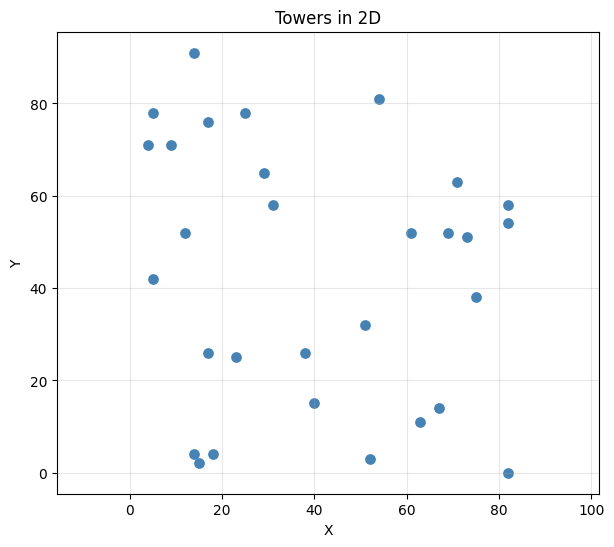

In [4]:
plot_towers("tests/test_2.txt")

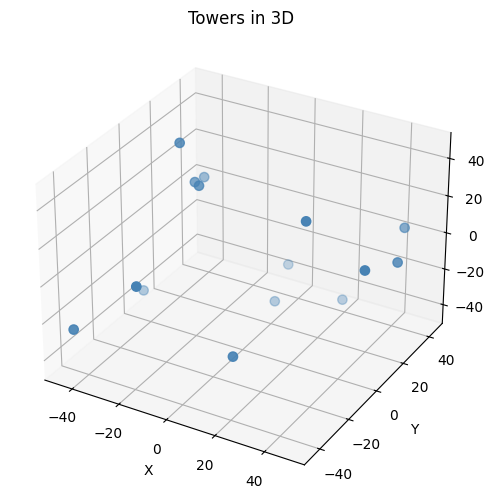

In [5]:
plot_towers("data/miniature_3d.data")

We have an idea of a greedy algorith - we will try to take a point on it's edge. Points that are strictly to the right-bottom, right-top, left-top and left-bottom. And starting from them add the tower which distance is the longest from the chosen one. And so on, and so on. But first, we will create a function compute the matrix of distances.

In [6]:
def distance_matrix(points):
    distances = pdist(points, metric="euclidean")
    return squareform(distances)

We have used `pdist()` function from scipy, because it is way faster than simple Numpy. Scipy calculates directly in C saving a lot of time. It also calculates distance for each pair of points once - without repetition.

In [7]:
def greedy_algorithm(D, number_to_keep, start_index):
    selected = [start_index]
    min_distance = None

    while len(selected) < number_to_keep:  # We iterate till we get number of towers to keep
        best_index = None
        best_distance = -1

        for i in range(len(D)):  # We iterate through every tower to calculate distance
            if i in selected:
                continue

            distances = []
            for j in selected:  # Here we add distances between our candidate i and each of already selected towers
                distances.append(D[i, j])

            nearest_distance = min(distances)  # We take minimum possible distance as a reference

            if nearest_distance > best_distance:  # We want to find the maximum minimum distance from every candidate
                best_distance = nearest_distance
                best_index = i

        selected.append(best_index)

        if min_distance is None or best_distance < min_distance:
            min_distance = best_distance

    return selected, round(min_distance, 3)

This should work, now we will write a function to get as a starting index for point thats on edge.

In [8]:
def get_starting_index(points, direction=0):
    """
    Return the index of the furthest point in the given direction.

    Directions 0 to 3 are top-right, bottom-right, top-left, bottom-left.
    In 3D, directions 0 to 3 use +z and directions 4 to 7 use -z.
    """
    dimension = points.shape[1]
    number_of_directions = 4 if dimension == 2 else 8

    if direction < 0 or direction >= number_of_directions:
        raise ValueError("Invalid starting direction.")

    x = points[:, 0]
    y = points[:, 1]

    if dimension == 2:
        scores = [x + y, x - y, -x + y, -x - y]

    if dimension == 3:
        z = points[:, 2]
        scores = [
            x + y + z, x - y + z, -x + y + z, -x - y + z,
            x + y - z, x - y - z, -x + y - z, -x - y - z,
        ]

    return int(scores[direction].argmax())

Now we think we are ready to create a test function so we'll be able to check how our algorithm will work for every file. This will be done in one function for simplicity.

In [9]:
def print_result(selected_points, min_distance):
    for point in selected_points:
        print(*point, sep="\t")
    print(f"{min_distance}")

In [10]:
def test_greedy_algorithm(filename: str, check=False):
    points, n, k, dimension = read_towers(filename)
    D = distance_matrix(points)
    minimum_distances = []
    selected_towers = []

    starting_point_str = ['top_right', 'bottom_right', 'top_left', 'bottom_left']
    if dimension == 3:
        starting_point_str = [
            "top_right_+z", "bottom_right_+z", "top_left_+z", "bottom_left_+z",
            "top_right_-z", "bottom_right_-z", "top_left_-z", "bottom_left_-z",
        ]

    starting_index = [get_starting_index(points, i) for i in range(len(starting_point_str))]

    # We will run the algorithm for each edge point to check which points should we choose as reference
    for i in range(len(starting_index)):
        selected, minimum_distance = greedy_algorithm(D, n - k, starting_index[i])
        minimum_distances.append(minimum_distance)
        selected_towers.append(selected)

    # If one want to see the four printed solutions the flag `check` must be switched on True
    if check:
        for i in range(len(starting_index)):
            print(starting_point_str[i])
            for k in selected_towers[i]:
                print(*points[k], sep="\t")
            print(f"{minimum_distances[i]}\n")

    # Here the function takes the index of the greatest minimum distance and returns it's point the distance
    best_distance = max(minimum_distances)
    best_index = minimum_distances.index(best_distance)
    return points[selected_towers[best_index]], best_distance

Our function is finished, now it's a big time for it to be testet on our data!

In [11]:
best_points, best_distance = test_greedy_algorithm("tests/test_1.txt", check=True)
print_result(best_points, best_distance)

top_right
1	0
0	1
1.414

bottom_right
1	0
0	1
1.414

top_left
0	1
1	0
1.414

bottom_left
0	0
1	0
1.0

1	0
0	1
1.414


In [12]:
best_points, best_distance = test_greedy_algorithm("tests/test_2.txt")
print_result(best_points, best_distance)

82	58
15	2
5	78
82	0
51	32
54	81
5	42
31	58
52	3
23	25
61	52
25	78
75	38
67	14
40	15
14	91
12	52
71	63
73	51
38	26
11.18


In [13]:
best_points, best_distance = test_greedy_algorithm("tests/test_3.txt")
print_result(best_points, best_distance)

985	908	744
54	34	57
336	113	951
966	176	148
6	941	160
266	838	976
823	961	128
329	488	392
796	126	765
518	12	167
155	11	546
566	484	852
919	501	585
145	484	16
630	910	495
73	480	884
966	566	183
515	178	549
25	342	540
700	377	67
151	261	276
733	659	372
301	736	42
404	762	337
56	165	980
986	930	361
428	448	110
95	610	583
596	853	759
586	614	593
918	205	407
747	395	314
306	434	814
60	840	843
648	62	381
798	932	889
742	57	101
812	739	48
433	675	825
212	249	632
24	780	2
157	868	311
311	106	307
738	608	927
386	786	558
237	19	753
541	496	416
493	192	757
755	638	685
271	531	587
1	29	242
848	209	9
823	91	513
363	117	628
494	135	328
321	328	186
245	641	453
428	545	264
163	478	700
368	224	506
486	308	152
400	698	976
72	592	93
195	11	92
39	675	698
755	957	756
847	567	255
216	525	868
113	184	384
440	441	842
133.51


In [14]:
best_points, best_distance = test_greedy_algorithm("data/miniature.data")
print_result(best_points, best_distance)

5	12
-19	-18
13	-17
-19	5
23.0


In [15]:
best_points, best_distance = test_greedy_algorithm("data/miniature_3d.data", check=True)
print_result(best_points, best_distance)

top_right_+z
42	44	2
-43	-44	-24
-30	6	47
-2	26	-43
9	-21	-35
48.929

bottom_right_+z
45	9	4
-43	-44	-24
-30	6	47
-2	26	-43
9	-21	-35
48.929

top_left_+z
-30	6	47
19	40	-44
-43	-44	-24
45	9	4
9	-21	-35
57.914

bottom_left_+z
-30	6	47
19	40	-44
-43	-44	-24
45	9	4
9	-21	-35
57.914

top_right_-z
19	40	-44
-30	6	47
-43	-44	-24
45	9	4
9	-21	-35
57.914

bottom_right_-z
9	-21	-35
-30	6	47
42	44	2
-45	3	-37
-4	39	-32
54.791

top_left_-z
-45	3	-37
42	44	2
-30	6	47
9	-21	-35
-4	39	-32
54.791

bottom_left_-z
-43	-44	-24
42	44	2
-30	6	47
-2	26	-43
9	-21	-35
48.929

-30	6	47
19	40	-44
-43	-44	-24
45	9	4
9	-21	-35
57.914


In [16]:
best_points, best_distance = test_greedy_algorithm("data/first_instance.data")
print_result(best_points, best_distance)

605	949
-782	-995
-997	962
882	-434
-205	-53
111	-887
-315	864
-850	-313
-753	289
404	-151
555.493


In [17]:
best_points, best_distance = test_greedy_algorithm("data/first_instance_3d.data")
print_result(best_points, best_distance)

481	-760	851
-833	704	-674
981	917	12
-555	856	988
-909	-995	-74
458	-979	-770
844	182	-915
157	77	175
-561	-615	955
119	919	-644
-724	-252	-735
-640	285	205
-92	-703	262
931	975	-804
830	-96	628
856	-438	-441
-76	-513	-458
121	817	242
75	-142	925
893	-860	243
741.221


In [18]:
best_points, best_distance = test_greedy_algorithm("data/large_instance.data")
print_result(best_points, best_distance)

9780	9519
-9896	-9818
9411	-9343
-9016	9560
222	179
-248	-9886
-9155	-238
392	9504
9781	-258
-4102	-4686
4696	-4930
5292	4889
-4230	5106
-9523	4652
5107	226
-9685	-4855
671	4757
-4457	9958
9795	-4867
-4458	658
4920	9273
4095	-9414
9985	4082
-5314	-8822
71	-5402
-6414	-2108
-7115	6844
-1909	-2280
1996	-2517
7512	-2521
7156	-7115
2855	2460
-6664	2808
-1924	2398
7336	2650
-8066	-7476
-2137	8009
8250	7131
2672	7576
-2325	-7987
1793	-7604
6829	-9867
-1819	5260
-9652	2243
-6337	-5797
-4597	7569
5135	-2162
7460	144
7374	-4861
-8756	-2429
2227.034


In [19]:
best_points, best_distance = test_greedy_algorithm("data/large_instance_3d.data")
print_result(best_points, best_distance)

-6468	-9771	-9315
7653	9343	9839
-9517	9912	-1185
8424	3908	-9803
-105	-9164	9374
9860	-8971	-1750
107	-39	-475
-8449	347	9756
-9601	-8330	2453
-6467	3059	-9715
9886	-4104	8641
3803	9980	-1175
-3480	9702	9339
3611	-5287	-8420
-9173	173	-1496
-445	-9426	275
8448	2598	3373
-35	319	8447
-904	9453	-9544
-9450	4928	4159
8904	-1516	-4951
-3319	6615	-3138
-7198	-9588	9961
3914	-4029	3931
9994	9427	2530
-5544	-3158	-6473
-9328	9417	-9518
1059	6703	4279
9882	7707	-4344
2593	4016	-5224
-4559	-4202	7384
8069	-9185	4355
-5052	-4820	-248
5954	3436	8913
-4584	8455	2656
-4688	643	3227
-895	-9031	-6835
8634	-8659	-8013
5560	9315	-8148
-9021	-7534	-4473
4440	-6813	-1287
-723	2831	-9546
2414	7772	9991
-9906	-4090	-9569
5468	160	-1055
-3783	1206	-3828
6299	-1058	-9981
-8605	6967	8895
-9754	-4300	7681
2709	-4718	8910
8598	-3271	1971
-3357	4639	8550
894	-2154	-4907
3197	2226	4020
-8146	7137	-5285
3969	-9305	-5533
-6895	5029	-252
5454	10000	4099
-569	-2292	4029
2243	5580	-568
9330	2817	-1418
4821	-8747	7773

Our algorithm worked well and fast for each of data file - we do hope POTUS and InPoczt will be satisfied from this solution.

*Konieczny Mateusz 257328 and Mikołaj Koszewski 257329*

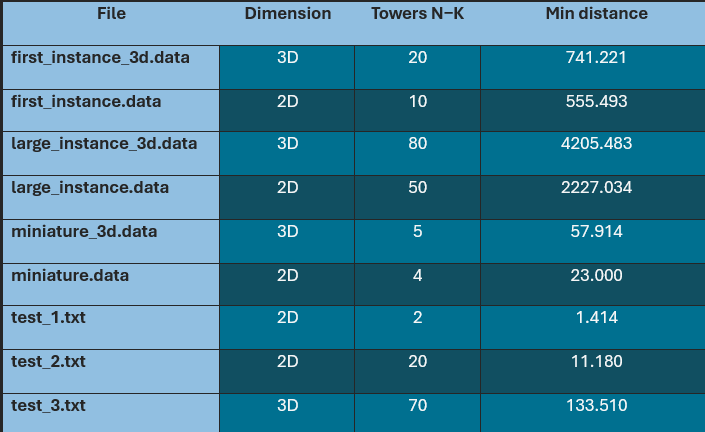

Below we have created the function for saving the files in desired format.

In [20]:
def save_result(selected_points, min_distance, filename):
    with open(filename, "w", encoding="utf-8") as file:
        for point in selected_points:
            coordinates = []
            for coordinate in point:
                coordinates.append(str(coordinate))

            file.write("\t".join(coordinates) + "\n")

        score = round(float(min_distance), 3)
        file.write(f"{score:.3f}\n")

In [21]:
filenames = [
    "miniature",
    "miniature_3d",
    "first_instance",
    "first_instance_3d",
    "large_instance",
    "large_instance_3d"
]

authors = "Mateusz_Konieczny_Mikolaj_Koszewski"

for name in filenames:
    best_points, best_distance = test_greedy_algorithm("data/" + name + ".data")
    save_result(
        best_points,
        best_distance,
        "solutions/" + authors + "_" + name + "_solution.txt"
    )

### TODO:

There is a need for creating sth more complex than what we have created.
1. Genetic Algorithm (opis jak dzialaja poszczegolne elementy - mutacja, krzyzowe)
2. Variable Neighbourhood Search

Wykres z wynikami, lub trajektoria wyboru celu. Histogram z greedy i tymi dwoma.
Krzywa progresji fn celu + porównanie.

In [ ]:
def random_towers(D, number_to_keep, rng):
    
    selected = []
    
    while len(selected) < number_to_keep:
        i = rng.integers(len(D))
        if i not in selected:
            selected.append(i)
            
    return selected

In [ ]:
def random_search(D, number_to_keep, budget, seed = None):
    
    rng = np.random.default_rng(seed)
    best_score = -np.inf
    best_towers = None
    history = []
    
    for i in range(budget):
        towers = random_towers(D, number_to_keep, rng)
        score, pair = closest_pair(D, towers)
        
        if score > best_score:
            best_score = score
            best_towers = towers
        
        history.append((i + 1, best_score))
    
    
    return best_towers, best_score, history
            

In [1]:
def closest_pair(D, selected):
    
    best_pair = None
    min_distance = np.inf
    

    for x, y in itertools.combinations(selected, 2):
        distance = D[x, y]
        if min_distance > distance:
            min_distance = distance
            best_pair = (x, y)
    

    return min_distance, best_pair                

In [ ]:
def crossover(parent_1, parent_2, number_to_keep, rng):
    
    child = []
    
    if tower in (parent_1 and parent_2):
        child.append(tower)
        
    elif tower in parent_1 or parent_2:
        pool.append(tower)
        
    while len(child) < len(number_to_keep):
        
        t = random_towers(pool, number_to_keep, rng)
        if t not in child:
            child.append(t)
            
    return child